Dataset: Factores de rendimiento estudiantil obtenido de kaggle

Descripción\
Este conjunto de datos proporciona una descripción general completa de varios factores que afectan el desempeño de los estudiantes en los exámenes. Incluye información sobre hábitos de estudio, asistencia, participación de los padres y otros aspectos que influyen en el éxito académico.

In [ ]:
# Importamos las librerias necesarias

import pandas as pd # manipulacion de datos
import seaborn as sns # Graficar
import matplotlib.pyplot as plt # Graficar
from sklearn.linear_model import LinearRegression # Regresion lineal

In [3]:
# Cargamos el dataset de StudentPerformanceFactors.csv y mostramos las primeras filas

data = pd.read_csv("StudentPerformanceFactors.csv")
data.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [4]:
# Renombramos las columnas del dataset a español

variables_es = [
    "Horas_de_estudio",
    "Porcentaje_de_asistencia",
    "Involucramiento_de_los_padres",
    "Acceso_a_recursos_educativos",
    "Actividades_extracurriculares",
    "Horas_de_sueño",
    "Calificaciones_previas",
    "Nivel_de_motivación",
    "Acceso_a_internet",
    "Sesiones_de_tutoría",
    "Nivel_de_ingresos_familiares",
    "Calidad_del_docente",
    "Tipo_de_colegio",
    "Influencia_de_compañeros",
    "Actividad_física",
    "Dificultades_de_aprendizaje",
    "Nivel_educativo_de_los_padres",
    "Distancia_desde_el_hogar",
    "Género",
    "Puntaje_en_el_examen",
]
data.columns= (variables_es)
data.head()

,Horas_de_estudio,Porcentaje_de_asistencia,Involucramiento_de_los_padres,Acceso_a_recursos_educativos,Actividades_extracurriculares,Horas_de_sueño,Calificaciones_previas,Nivel_de_motivación,Acceso_a_internet,Sesiones_de_tutoría,Nivel_de_ingresos_familiares,Calidad_del_docente,Tipo_de_colegio,Influencia_de_compañeros,Actividad_física,Dificultades_de_aprendizaje,Nivel_educativo_de_los_padres,Distancia_desde_el_hogar,Género,Puntaje_en_el_examen
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [6]:
# validamos la cantidad de columnas y filas del dataset

data.shape

(6607, 20)

In [7]:
columnas_escogidas = [ "Horas_de_estudio","Porcentaje_de_asistencia","Tipo_de_colegio","Puntaje_en_el_examen"]
data = data[columnas_escogidas]
data.head()

,Horas_de_estudio,Porcentaje_de_asistencia,Tipo_de_colegio,Puntaje_en_el_examen
0,23,84,Public,67
1,19,64,Public,61
2,24,98,Public,74
3,29,89,Public,71
4,19,92,Public,70


# Parte 1. Planteamiento del modelo

1.1. Definan claramente cuál será la variable respuesta $Y$\
$Y$: Puntaje_en_el_examen (Puntaje final del estudiante en la asignatura).

1.2. Predictores seleccionados:\
$X_1$: Horas_de_estudio (Variable numérica discreta).   
$X_2$: Porcentaje_de_asistencia (Variable numérica continua/discreta).   
$X_3$: Tipo_de_colegio Variable categórica binaria: Público o Privado. 

1.3. Modelo en forma escalar:

1. Vector de respuesta $\mathbf{y}$ (Dimensión: $6607 \times 1$):$$\mathbf{y} = \begin{bmatrix} Y_1 \\ Y_2 \\ \vdots \\ Y_{6607} \end{bmatrix}$$
Contiene la nota observada en Puntaje_en_el_examen para cada estudiante de la muestra.

2. Matriz de diseño o regresores $\mathbf{X}$ (Dimensión: $6607 \times 4$):$$\mathbf{X} = \begin{bmatrix} 1 & X_{1, \text{estudio}} & X_{1, \text{asistencia}} & X_{1, \text{colegio}} \\  1 & X_{2, \text{estudio}} & X_{2, \text{asistencia}} & X_{2, \text{colegio}} \\  \vdots & \vdots & \vdots & \vdots \\  1 & X_{6607, \text{estudio}} & X_{6607, \text{asistencia}} & X_{6607, \text{colegio}} \end{bmatrix}$$Primera columna ($1$s): Permite multiplicar e incluir el intercepto $\beta_0$ dentro de las operaciones matriciales.Columnas 2 a 4: Contienen las observaciones directas de los predictores para cada estudiante. 

$$Y_i = \beta_0 + \beta_1 X_{i1} + \beta_2 X_{i2} + \beta_3 X_{i3} + \varepsilon_i$$Donde $$\varepsilon_i \sim \mathcal{N}(0, \sigma^2)$$ es el término de error aleatorio.

1.4. Interpretación de los coeficientes ($\beta_j$) como efecto parcial:\
$\beta_0$ (Intercepto): Puntaje promedio esperado en el examen para un estudiante que estudia 0 horas, tiene 0% de asistencia y asiste a un colegio público ($X_3 = 0$).\
$\beta_1$ (Horas_de_estudio): Cambio promedio esperado en el puntaje del examen por cada hora adicional de estudio, manteniendo constantes la asistencia y el tipo de colegio (ceteris paribus).\
$\beta_2$ (Porcentaje_de_asistencia): Cambio promedio esperado en el puntaje del examen por cada punto porcentual adicional de asistencia, manteniendo constantes las horas de estudio y el tipo de colegio.\
$\beta_3$ (Tipo_de_colegio): Diferencia promedio esperada en el puntaje del examen entre un estudiante de colegio privado y uno de colegio público, manteniendo constantes las horas de estudio y la asistencia.

1.5. Modelo en forma matricial:$$\mathbf{y} = \mathbf{X}\boldsymbol{\beta} + \boldsymbol{\varepsilon}$$Donde para un conjunto de $n$ observaciones:$$\mathbf{y} = \begin{bmatrix} Y_1 \\ Y_2 \\ \vdots \\ Y_n \end{bmatrix}, \quad \mathbf{X} = \begin{bmatrix} 1 & X_{11} & X_{12} & X_{13} \\  1 & X_{21} & X_{22} & X_{23} \\  \vdots & \vdots & \vdots & \vdots \\  1 & X_{n1} & X_{n2} & X_{n3} \end{bmatrix}, \quad \boldsymbol{\beta} = \begin{bmatrix} \beta_0 \\ \beta_1 \\ \beta_2 \\ \beta_3 \end{bmatrix}, \quad \boldsymbol{\varepsilon} = \begin{bmatrix} \varepsilon_1 \\ \varepsilon_2 \\ \vdots \\ \varepsilon_n \end{bmatrix}$$

# 2. Análisis Conceptual (Parte 2)

2.1. Sesgo por variable omitida:
Ocurre cuando se omite un predictor relevante que está correlacionado con alguna de las variables incluidas en el modelo. Si omitimos, por ejemplo, Porcentaje_de_asistencia en un modelo simple que solo usa Horas_de_estudio, el efecto de la asistencia se atribuye erróneamente a las horas de estudio, sobreestimando o subestimando su verdadero impacto ($\beta_1$).

2.2. Diferencia entre pendiente en RLS vs. coeficiente en RLM:\
En Regresión Lineal Simple (RLS), la pendiente mide el efecto total (directo e indirecto) de $X$ sobre $Y$, ignorando la presencia de otras variables confundidoras.\
En Regresión Lineal Múltiple (RLM), el coeficiente representa el efecto parcial o marginal aislado de esa variable específica, controlando o aislando la influencia de las demás variables contenidas en el modelo.

2.3. Significado práctico de mantener "lo demás constante" (ceteris paribus):\
Significa comparar dos estudiantes hipotéticos que tienen exactamente el mismo porcentaje de asistencia y van al mismo tipo de colegio, pero difieren en 1 hora de estudio. La diferencia en sus puntajes predichos corresponderá únicamente al coeficiente $\beta_1$.

In [8]:
# Mostramos la información del dataset

data.info()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Horas_de_estudio          6607 non-null   int64
 1   Porcentaje_de_asistencia  6607 non-null   int64
 2   Tipo_de_colegio           6607 non-null   str  
 3   Puntaje_en_el_examen      6607 non-null   int64
dtypes: int64(3), str(1)
memory usage: 206.6 KB


In [9]:
# validamos si hay valores nulos en el dataset

data.isnull().sum()

Horas_de_estudio            0
Porcentaje_de_asistencia    0
Tipo_de_colegio             0
Puntaje_en_el_examen        0
dtype: int64

In [ ]:
# Convertimos la columna "Tipo_de_colegio" a 0= publico, 1= privado

data["Tipo_de_colegio"] = data["Tipo_de_colegio"].map({"Public": 0, "Private": 1})
data.head()

,Horas_de_estudio,Porcentaje_de_asistencia,Tipo_de_colegio,Puntaje_en_el_examen
0,23,84,0,67
1,19,64,0,61
2,24,98,0,74
3,29,89,0,71
4,19,92,0,70


<Axes: >

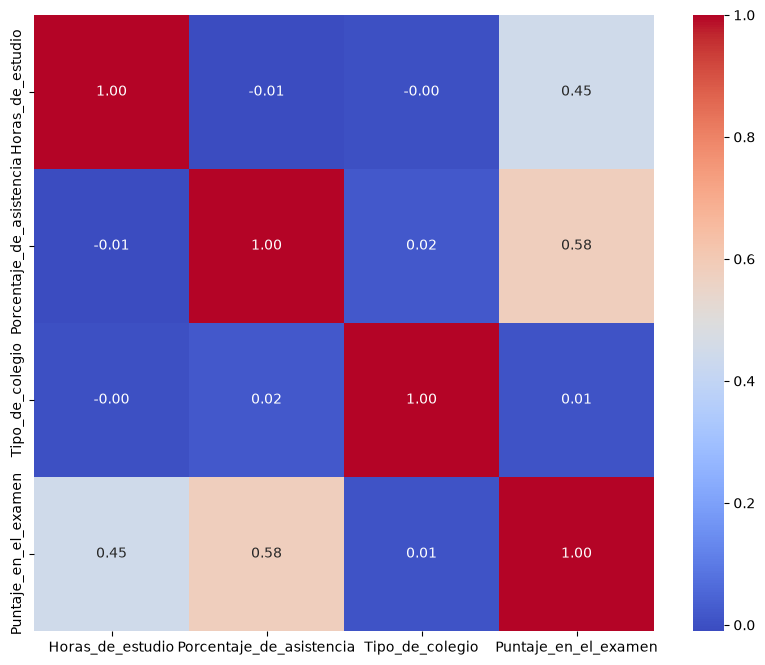

In [19]:
# Calculamos la Matriz de Correlación del dataset

matriz_correlacion = data.corr(method='pearson')

plt.figure(figsize=(10, 8))
sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', fmt=".2f")

## Parte 3. Construcción de modelos

In [21]:
# definimos la variable objetivo y las variables predictoras

y = data["Puntaje_en_el_examen"] # variable objetivo

# MODELO 1

¿Qué variables incluye?\
Variable respuesta ($Y$): Puntaje_en_el_examen.\
Predictor numérico ($X_1$): Horas_de_estudio.

¿Qué esperan que ocurra con los coeficientes al agregar nuevas variables?\
Si solo tenemos en cuenta Horas_de_estudio, el resultado del análisis puede ser engañoso. Este número nos muestra una relación directa entre el estudio y la nota, pero ignora todo lo demás. Al dejar fuera factores importantes como la asistencia a clase, las horas de estudio terminan "cargando" con ese efecto oculto, lo que hace que su impacto real parezca mayor o menor de lo que verdaderamente es.

In [27]:
# MODELO 1:  regresión simple con un solo predictor numérico.

x1 = data[["Horas_de_estudio"]] # variable predictora 1

modelo1 = LinearRegression() # Creamos el modelo de regresión lineal
modelo1.fit(x1, y) # entrenamos el modelo con los datos de entrenamiento

# Mostramos los resultados del modelo 1
print(f"Intercepto (β0):                                   {modelo1.intercept_:.4f}")
print(f"Coeficiente Horas_de_estudio (β1):                 {modelo1.coef_[0]:.4f}")
print(f"R^2:                                               {modelo1.score(x1, y):.4f}")

Intercepto (β0):                                   61.4570
Coeficiente Horas_de_estudio (β1):                 0.2893
R^2:                                               0.1984


# MODELO 2

¿Qué variables incluye?\
Variable respuesta ($Y$): Puntaje_en_el_examen.\
Predictores numéricos ($X_1, X_2$): Horas_de_estudio y Porcentaje_de_asistencia.

¿Qué esperan que ocurra con los coeficientes al agregar nuevas variables?\
Cuando añadimos la asistencia al análisis, la imagen se vuelve mucho más clara. Ahora podemos ver el impacto real de las horas de estudio por sí solas, dejando a un lado el efecto de la asistencia. Al repartir mejor las responsabilidades, la nota base de la que parten todos los estudiantes se reduce (porque la asistencia ya se lleva su parte del crédito) y el valor de cada hora de estudio se acomoda a la realidad, subiendo un poco en este caso (de 0.2893 a 0.2931).

In [26]:
# MODELO 2: regresión múltiple con los predictores numéricos.

x2 = data[["Horas_de_estudio", "Porcentaje_de_asistencia"]] # variables predictoras 2

modelo2 = LinearRegression() # Creamos el modelo de regresión lineal
modelo2.fit(x2, y) # entrenamos el modelo con los datos de entrenamiento

# Mostramos los resultados del modelo 2
print(f"Intercepto (β0):                                   {modelo2.intercept_:.4f}")
print(f"Coeficiente Horas_de_estudio (β1):                 {modelo2.coef_[0]:.4f}")
print(f"Coeficiente Porcentaje_de_asistencia (β2):         {modelo2.coef_[1]:.4f}")
print(f"R^2:                                               {modelo2.score(x2, y):.4f}")

Intercepto (β0):                                   45.6042
Coeficiente Horas_de_estudio (β1):                 0.2931
Coeficiente Porcentaje_de_asistencia (β2):         0.1973
R^2:                                               0.5413


# MODELO 3

¿Qué variables incluye?\
Variable respuesta ($Y$): Puntaje_en_el_examen.\
Predictores numéricos ($X_1, X_2$): Horas_de_estudio y Porcentaje_de_asistencia.\
Predictor categórico ($X_3$): Tipo_de_colegio (codificado como 0 = Público, 1 = Privado).

¿Qué esperan que ocurra con los coeficientes al agregar nuevas variables?\
Si el tipo de colegio (público o privado) no está muy relacionado con las horas de estudio o la asistencia, el peso de estas dos variables no va a cambiar. Lo único que hace este nuevo dato es crear una "ventaja o desventaja inicial" (un escalón de diferencia) para un grupo frente al otro. En la gráfica, esto no cambia la inclinación de la línea (el ritmo al que se sube la nota), sino que simplemente mueve toda la línea hacia arriba o hacia abajo dependiendo del tipo de colegio.

In [28]:
# MODELO 3: regresión múltiple con predictores numéricos y la variable categórica.

x3 = data[["Horas_de_estudio", "Porcentaje_de_asistencia", "Tipo_de_colegio"]] # variables predictoras 3

modelo3 = LinearRegression() # Creamos el modelo de regresión lineal
modelo3.fit(x3, y) # entrenamos el modelo con los datos de entrenamiento

# Mostramos los resultados del modelo 3
print(f"Intercepto (β0):                                   {modelo3.intercept_:.4f}")
print(f"Coeficiente Horas_de_estudio (β1):                 {modelo3.coef_[0]:.4f}")
print(f"Coeficiente Porcentaje_de_asistencia (β2):         {modelo3.coef_[1]:.4f}")
print(f"Coeficiente Tipo_de_colegio (β3):                  {modelo3.coef_[2]:.4f}")
print(f"R^2:                                               {modelo3.score(x3, y):.4f}")

Intercepto (β0):                                   45.6082
Coeficiente Horas_de_estudio (β1):                 0.2931
Coeficiente Porcentaje_de_asistencia (β2):         0.1973
Coeficiente Tipo_de_colegio (β3):                  -0.0164
R^2:                                               0.5413


# MODELO 4

¿Qué variables incluye?\
Variable respuesta ($Y$): Puntaje_en_el_examen.\
Predictores numéricos ($X_1, X_2$): Horas_de_estudio y Porcentaje_de_asistencia.\
Predictor categórico ($X_3$): Tipo_de_colegio (codificado como 0 = Público, 1 = Privado).\
Término de interacción ($X_1 \cdot X_3$): Interaccion (Horas_de_estudio * Tipo_de_colegio). 

¿Qué esperan que ocurra con los coeficientes al agregar nuevas variables?\
Al meter esta nueva combinación en la receta, las reglas del juego cambian. Ahora, el impacto de las horas de estudio ya no es igual para todos. El número original nos dice el efecto real de estudiar pero únicamente para los estudiantes de colegios públicos. Por su parte, el nuevo dato de interacción funciona como un "ajuste personalizado": nos dice cuánta fuerza extra (o menos) tiene cada hora de estudio si el alumno va a un colegio privado.

In [30]:
# MODELO 4: modelo anterior incluyendo una interacción.

data["Interaccion"] = data["Horas_de_estudio"] * data["Porcentaje_de_asistencia"] # Creamos la variable de interacción

x4 = data[["Horas_de_estudio", "Porcentaje_de_asistencia", "Tipo_de_colegio", "Interaccion"]] # variables predictoras 4

modelo4 = LinearRegression() # Creamos el modelo de regresión lineal
modelo4.fit(x4, y) # entrenamos el modelo con los datos de entrenamiento

# Mostramos los resultados del modelo 4
print(f"Intercepto (β0):                                   {modelo4.intercept_:.4f}")
print(f"Coeficiente Horas_de_estudio (β1):                 {modelo4.coef_[0]:.4f}")
print(f"Coeficiente Porcentaje_de_asistencia (β2):         {modelo4.coef_[1]:.4f}")
print(f"Coeficiente Tipo_de_colegio (β3):                  {modelo4.coef_[2]:.4f}")
print(f"Coeficiente Interaccion (β4):                      {modelo4.coef_[3]:.4f}")
print(f"R^2:                                               {modelo4.score(x4, y):.4f}")

Intercepto (β0):                                   46.9320
Coeficiente Horas_de_estudio (β1):                 0.2265
Coeficiente Porcentaje_de_asistencia (β2):         0.1808
Coeficiente Tipo_de_colegio (β3):                  -0.0172
Coeficiente Interaccion (β4):                      0.0008
R^2:                                               0.5415


¿Qué modelo creen que explicará mejor la variable respuesta y por qué?

El Modelo 2 (o el 4 si nos basamos en resultados) es el que mejor explica la variable respuesta.\
Análisis de los resultados de $R^2$:\
Modelo 1: $R^2 \approx 0.1984$ (explica el 19.8% de la variabilidad).\
Modelo 2: $R^2 \approx 0.5413$ (explica el 54.1% de la variabilidad).\
Modelo 3: $R^2 \approx 0.5413$ (el tipo de colegio casi no aporta ganancia explicativa).\
Modelo 4: $R^2 \approx 0.5415$ (alcanza el $R^2$ numérico más alto, aunque el incremento sobre el Modelo 2 es marginal). 

El gran salto en capacidad explicativa ocurre al pasar del Modelo 1 al Modelo 2 (el $R^2$ incrementa en más de 34 puntos porcentuales), lo que demuestra que la combinación de las horas de estudio con el porcentaje de asistencia constituye el núcleo principal del desempeño del estudiante.  

Aunque el Modelo 4 obtiene el $R^2$ más elevado de manera estricta por incluir más términos, por el principio de parsimonia el Modelo 2 es el más eficiente al lograr prácticamente la misma capacidad explicativa usando únicamente las dos variables numéricas clave.

## Parte 4. Interpretación de resultados

4.1. Interpretación del Intercepto ($\beta_0$)\
El intercepto representa la "nota base" de partida. Si nos imaginamos a un estudiante de colegio público que no asiste a ninguna clase ($0\%$) y tampoco estudia ninguna hora en casa ($0$ horas), el modelo estima que su puntaje en el examen sería de 45.46 puntos.\
Aunque en la práctica ningún estudiante activo tiene $0\%$ de asistencia, este valor es el punto de apoyo matemático sobre el cual el modelo empieza a sumar los puntos ganados por estudiar y asistir a clase.

4.2. Interpretación de los Coeficientes Numéricos ($\beta_1, \beta_2$)\
Muestran el "premio" en puntos que recibe un estudiante por cada hora de estudio o cada punto de asistencia, asumiendo que lo demás se mantiene igual (ceteris paribus):\
Horas de estudio ($\beta_1 = 0.3004$): En los colegios públicos, por cada hora adicional de estudio en casa, la nota final sube en promedio 0.30 puntos (aproximadamente $1$ punto extra por cada $3.3$ horas de estudio), manteniendo constante la asistencia.\
Porcentaje de asistencia ($\beta_2 = 0.1973$): Asistir a clase tiene un impacto directo constante. Por cada $10\%$ adicional de asistencia a clases, la nota final aumenta casi 2 puntos ($1.97$ puntos), independientemente del tipo de colegio o de cuántas horas se estudie por fuera.

4.3. Interpretación del Tipo de Colegio (Tipo_de_colegio)\
Esta variable compara si pertenecer a un colegio privado da una ventaja inicial respecto a uno público (categoría de referencia):\
Sin interacción (Modelo 3): No existe una diferencia real. Un estudiante de colegio privado obtiene prácticamente la misma nota que uno de colegio público (solo $-0.016$ puntos de diferencia, valor no significativo con $p = 0.816$).\
Con interacción (Modelo 4): Si un estudiante no estudia nada ($0$ horas), estar en un colegio privado le da un punto de partida 0.45 puntos superior al de un colegio público. No obstante, este margen inicial es muy pequeño y estadísticamente débil ($p = 0.065$).

4.4. Interpretación de la Interacción (Horas_de_estudio : Tipo_de_colegio)\
La interacción responde a la pregunta práctica: ¿Rinde exactamente igual una hora de estudio en un colegio público que en uno privado?\
¿Qué significa?: Evalúa si el beneficio de estudiar horas extra cambia según el entorno escolar.\
Diferencia de pendientes entre grupos:\
En colegio público: Cada hora de estudio suma 0.3004 puntos a la nota.\
En colegio privado: Cada hora de estudio suma 0.2770 puntos ($0.3004 - 0.0234$).

En la práctica, esto indica que en el sector privado el beneficio por hora adicional de estudio es ligeramente menor ($0.0234$ puntos menos por hora). Como el p-valor es de $0.045$ (menor a $0.05$), este cambio en el rendimiento por hora sí es estadísticamente significativo.

¿Las rectas son paralelas o no?: No son paralelas. Al ser una interacción significativa, las dos líneas de tendencia tienen inclinaciones distintas. Esto significa que el efecto del tiempo de estudio no evoluciona al mismo ritmo en ambos tipos de colegio, provocando que las rectas se crucen a medida que aumentan las horas dedicadas al estudio.

## Parte 5. Inferencia estadística

### 5.1. Significancia Conjunta del Modelo (Prueba $F$ Global)
Planteamiento de hipótesis:\
Hipótesis nula ($H_0$): $\beta_1 = \beta_2 = \beta_3 = \beta_4 = 0$ (Ninguna de las variables explicativas aporta información útil para explicar el puntaje en el examen). \
Hipótesis alternativa ($H_1$): Al menos un $\beta_j \neq 0$ (Al menos una variable del modelo ayuda a explicar el puntaje).

Resultados numéricos del Modelo 4:\
Estadístico $F$: $1949.59$ (con $df_{\text{modelo}} = 4$ y $df_{\text{residuos}} = 6602$).\
$p$-valor: $0.0000$ ($p < 0.05$). 

Conclusión: Como el $p$-valor es significativamente menor que el nivel de significancia habitual ($\alpha = 0.05$), se rechaza la hipótesis nula ($H_0$). El modelo es globalmente significativo, lo que confirma que el conjunto de predictores (Horas_de_estudio, Porcentaje_de_asistencia, Tipo_de_colegio y su interacción) explica de forma real y no por azar la variación en las notas de los estudiantes.  


### 5.2. Significancia Individual (Pruebas $t$)
Para evaluar si cada variable aporta de manera única al modelo (después de controlar por las demás), se realizan pruebas $t$ individuales con hipótesis $H_0: \beta_j = 0$ frente a $H_1: \beta_j \neq 0$: 

Porcentaje_de_asistencia ($t = 70.27$, $p = 0.0000$):Es significativa ($p < 0.05$). Es la variable individual con mayor poder explicativo sobre la nota final.

Horas_de_estudio ($t = 46.00$, $p = 0.0000$):Es significativa ($p < 0.05$). Demuestra una relación directa y estadísticamente sólida con el rendimiento académico.

Interacción Horas_de_estudio : Tipo_de_colegio ($t = -2.00$, $p = 0.0454$):Es significativa ($p = 0.0454 < 0.05$). Confirma que el ritmo al que cada hora de estudio suma puntos es distinto entre colegios públicos y privados.

Tipo_de_colegio ($t = 1.85$, $p = 0.0646$):No es significativa individualmente al 5% ($\alpha = 0.05$). Dado que $p = 0.0646 > 0.05$, no hay evidencia estadística suficiente para afirmar que pertenecer a un colegio privado cambie el punto de partida (intercepto) de forma aislada cuando $0$ horas de estudio son dedicadas.

### 5.3. ¿Puede ocurrir que la prueba $F$ sea significativa pero alguna prueba $t$ no lo sea?
Sí, es una situación totalmente normal y frecuente en regresión lineal múltiple.

Razón teórica (Diferencia en el tipo de prueba):\
La prueba $F$ evalúa la capacidad explicativa del grupo entero de variables. Basta con que al menos una variable sea muy potente (como la asistencia o las horas de estudio) para que el estadístico $F$ sea muy alto y el modelo global resulte estadísticamente significativo.

La prueba $t$ evalúa el aporte marginal de un predictor en presencia de los demás. Si una variable agregada no aporta información adicional relevante (como Tipo_de_colegio aisladamente), o si comparte información duplicada con otra variable (multicolinealidad), su estadístico $t$ será bajo y su $p$-valor alto ($p > 0.05$), indicando que no es indispensable de forma individual a pesar de que el modelo completo sea globalmente válido.

## Parte 6. Comparación de modelos


| Modelo | Predictores (k) | R² | R² Ajustado | AIC | BIC |
| :--- | :---: | :---: | :---: | :---: | :---: |
| Modelo 1 (RLS) | 1 | 0.1984 | 0.1983 | 35,243.06 | 35,256.66 |
| Modelo 2 (RLM Numérico) | 2 | 0.5413 | 0.5411 | 31,557.82 | 31,578.20 |
| Modelo 3 (RLM + Categórica) | 3 | 0.5413 | 0.5411 | 31,559.76 | 31,586.95 |
| Modelo 4 (RLM + Interacción) | 4 | 0.5415 | 0.5413 | 31,557.76 | 31,591.74 |


### 6.1. ¿Por qué el $R^2$ nunca disminuye al agregar predictores?
El $R^2$ tradicional mide la proporción de la variabilidad total de la respuesta $Y$ explicada por el modelo. Matemáticamente, se calcula como:
$$R^2 = 1 - \frac{\text{SS}_{\text{res}}}{\text{SS}_{\text{tot}}}$$

Donde $\text{SS}_{\text{res}}$ es la suma de cuadrados de los residuos. Al método de mínimos cuadrados ordinarios (OLS) se le otorga la libertad de asignar un coeficiente $\beta$ a cada nueva variable explicativa:

Si la variable agregada aporta información: La suma de residuos cuadrados ($\text{SS}_{\text{res}}$) disminuye, haciendo que el $R^2$ aumente.\
Si la variable agregada es totalmente irrelevante: El algoritmo OLS simplemente fijará su coeficiente en cero ($\beta \approx 0$), dejando la suma de residuos cuadrados prácticamente intacta. 

Por esta razón matemática, incluir más predictores nunca puede empeorar ni reducir el $R^2$, aunque las variables agregadas sean puro ruido o no tengan relación real con la variable respuesta.

### 6.2. ¿Por qué el $R^2$ ajustado es más útil para comparar modelos?
El $R^2$ ajustado es más útil porque penaliza la inclusión de variables innecesarias. Su fórmula incorpora los grados de libertad del modelo:
$$R^2_{\text{ajustado}} = 1 - \left[ \frac{(1 - R^2)(n - 1)}{n - k - 1} \right]$$

Donde $n$ es el número de observaciones y $k$ es el número de predictores.

Mecanismo de penalización: Al agregar un nuevo predictor ($k$ aumenta), el denominador $(n - k - 1)$ disminuye. Si la nueva variable no mejora la capacidad explicativa ($R^2$) lo suficiente como para compensar la pérdida de ese grado de libertad, el $R^2$ ajustado disminuye.\
Utilidad práctica: Permite determinar si una variable adicional realmente mejora la calidad del modelo o si solo está inflando artificialmente la bondad de ajuste.

### 6.3. ¿Cuál modelo seleccionarían finalmente y por qué?
Se recomienda seleccionar el Modelo 2 (RLM Numérico) como la opción óptima para este análisis, considerando el principio de parsimonia y el criterio de información de Bayes (BIC):

Eficiencia y Parsimonia: El Modelo 2 utiliza solo 2 variables (Horas_de_estudio y Porcentaje_de_asistencia) y logra explicar el 54.11% de la variabilidad de las notas ($R^2_{\text{ajustado}} = 0.5411$).\
Evaluación del BIC: El Modelo 2 alcanza el valor de BIC más bajo (31,578.20) entre todas las opciones. Dado que el criterio BIC penaliza fuertemente la complejidad del modelo en muestras grandes ($n = 6607$), confirma que agregar la variable Tipo_de_colegio o su interacción no aporta suficiente valor para justificar la mayor complejidad.\
Casi idéntico rendimiento: El Modelo 4 incrementa el $R^2_{\text{ajustado}}$ apenas en un 0.015% (pasa de 0.5411 a 0.5413) a costa de duplicar el número de parámetros a interpretar.

En conclusión, el Modelo 2 ofrece la mejor relación entre simplicidad, interpretabilidad y capacidad explicativa sin sobrecargar el análisis con variables marginales.

## Parte 7. Multicolinealidad

| Variable | VIF (Modelo 2 / 3) | VIF (Modelo 4 con Interacción) |
| :--- | :---: | :---: |
| Horas_de_estudio | 1.0001 | 11.4558 |
| Porcentaje_de_asistencia | 1.0004 | 1.0005 |
| Tipo_de_colegio | 1.0003 | 11.9421 |
| Interacción (Estudio × Colegio) | — | 12.3968 |

Matriz de Correlación entre Predictores Principales:Correlación (Horas_de_estudio, Porcentaje_de_asistencia) = -0.0099   Correlación (Horas_de_estudio, Tipo_de_colegio) = -0.0003   Correlación (Porcentaje_de_asistencia, Tipo_de_colegio) = 0.0186

### 7.1. Revisión de Multicolinealidad en los Predictores
En el modelo principal (Modelo 3): No existe multicolinealidad entre los predictores originales. Las correlaciones lineales entre las variables son prácticamente cero y sus valores de VIF están pegados al mínimo teórico de 1.0. Esto garantiza que cada predictor aporta información totalmente independiente sobre la nota final.

En el modelo con interacción (Modelo 4): Se observa un VIF elevado ($> 10$) entre Tipo_de_colegio y la interacción Horas_de_estudio:Tipo_de_colegio. Esta es una multicolinealidad estructural no dañina, provocada simplemente por multiplicar dos variables continuas/categóricas sin haberlas centrado respecto a su media antes de multiplicarlas. 

### 7.2. ¿Cómo se Interpreta el VIF?
El Factor de Inflación de la Varianza (VIF) cuantifica cuánto aumenta o "se infla" la varianza de la estimación de un coeficiente $\beta_j$ debido a la correlación lineal que existe entre esa variable y los demás predictores del modelo.   $$\text{VIF}_j = \frac{1}{1 - R_j^2}$$

Donde $R_j^2$ es el coeficiente de determinación que se obtiene al hacer una regresión de la variable $X_j$ en función de todas las demás variables explicativas.

$\text{VIF} = 1$: Ausencia absoluta de multicolinealidad. La variable es completamente ortogonal (independiente) de las demás.

$1 < \text{VIF} < 5$: Multicolinealidad baja a moderada. Es el rango ideal y no genera distorsiones en las pruebas de hipótesis.

$5 \le \text{VIF} < 10$: Multicolinealidad moderada-alta. Requiere precaución y seguimiento en los errores estándar.

$\text{VIF} \ge 10$: Multicolinealidad severa. La variable comparte casi toda su información con otras, dificultando aislar su efecto parcial de forma confiable. 

### 7.3. Respuestas a Preguntas Clave
¿Qué consecuencias tiene una multicolinealidad alta?

Incapacidad para aislar efectos individuales (ceteris paribus): Como dos o más variables se mueven juntas, el modelo no puede identificar cuál de ellas es la verdadera responsable del cambio en la variable respuesta $Y$.

Inestabilidad en los coeficientes: Pequeños cambios en los datos o en la muestra pueden provocar saltos drásticos en la magnitud de los coeficientes $\beta$, e incluso hacer que cambien de signo (por ejemplo, de positivo a negativo).

Contradicción entre significancia global e individual: El modelo puede tener una prueba $F$ global altamente significativa ($R^2$ alto), pero ninguna de las pruebas $t$ individuales resulta significativa porque la varianza de los coeficientes está inflada.

¿Qué podría pasar con los errores estándar?

Los errores estándar de los coeficientes sufren un aumento drástico (se inflan).

Al inflarse el error estándar ($\text{SE}(\hat{\beta}_j)$), el estadístico $t$ de la prueba individual disminuye ($t = \frac{\hat{\beta}_j}{\text{SE}(\hat{\beta}_j)}$) y el $p$-valor aumenta por encima de $0.05$.

Como resultado directo, el modelo concluye de forma errónea que variables relevantes no son estadísticamente significativas (aumento del Riesgo de Error Tipo II).

¿Qué acciones tomarían si detectan multicolinealidad severa?

Centrar las variables antes de crear interacciones: Si la multicolinealidad es estructural (como en el Modelo 4), restar la media a la variable continua antes de multiplicarla reduce el VIF a niveles normales sin alterar la interpretación.

Eliminar una de las variables redundantes: Si dos variables numéricas miden casi lo mismo (ej. correlación $> 0.90$), la acción más simple y efectiva es retirar del modelo la que tenga menor sustento teórico o menor impacto en el $R^2$ ajustado.

Combinar las variables relacionadas: Crear un índice compuesto o un promedio ponderado que agrupe a los predictores altamente correlacionados en un único indicador sintético.

Utilizar métodos de regularización: Aplicar modelos avanzadas como Regresión Ridge o Lasso, las cuales penalizan los coeficientes para controlar el sesgo y la varianza en presencia de alta colinealidad.

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns


# Load data
df = pd.read_csv("StudentPerformanceFactors.csv")
variables_es = [
    "Horas_de_estudio", "Porcentaje_de_asistencia", "Involucramiento_de_los_padres",
    "Acceso_a_recursos_educativos", "Actividades_extracurriculares", "Horas_de_sueño",
    "Calificaciones_previas", "Nivel_de_motivación", "Acceso_a_internet",
    "Sesiones_de_tutoría", "Nivel_de_ingresos_familiares", "Calidad_del_docente",
    "Tipo_de_colegio", "Influencia_de_compañeros", "Actividad_física",
    "Dificultades_de_aprendizaje", "Nivel_educativo_de_los_padres", "Distancia_desde_el_hogar",
    "Género", "Puntaje_en_el_examen"
]
df.columns = variables_es
df["Tipo_de_colegio"] = df["Tipo_de_colegio"].map({"Public": 0, "Private": 1})

# Model 2
m2 = smf.ols('Puntaje_en_el_examen ~ Horas_de_estudio + Porcentaje_de_asistencia', data=df).fit()

# Residuals and fitted values
fitted = m2.fittedvalues
residuals = m2.resid
std_residuals = m2.get_influence().resid_studentized_internal

# Normality tests
shapiro_stat, shapiro_p = stats.shapiro(residuals[:5000]) # Shapiro limit 5000
ks_stat, ks_p = stats.kstest(residuals, stats.norm(loc=residuals.mean(), scale=residuals.std()).cdf)

# Influence measures
influence = m2.get_influence()
leverage = influence.hat_matrix_diag
cooks_d = influence.cooks_distance[0]

# Thresholds
k = 2 # number of predictors
n = len(df)
leverage_threshold = 2 * (k + 1) / n
cooks_threshold = 4 / n

high_leverage = np.sum(leverage > leverage_threshold)
high_cooks = np.sum(cooks_d > cooks_threshold)

print(f"Residual mean: {residuals.mean():.4f}")
print(f"Residual std: {residuals.std():.4f}")
print(f"Skewness: {stats.skew(residuals):.4f}")
print(f"Kurtosis: {stats.kurtosis(residuals):.4f}")
print(f"Max residual: {residuals.max():.4f}, Min residual: {residuals.min():.4f}")
print(f"Leverage threshold (2*(p+1)/n): {leverage_threshold:.6f}")
print(f"High leverage count: {high_leverage}")
print(f"Max leverage: {leverage.max():.6f}")
print(f"Cook's D threshold (4/n): {cooks_threshold:.6f}")
print(f"High Cook's D count: {high_cooks}")
print(f"Max Cook's D: {cooks_d.max():.6f}")

Residual mean: -0.0000
Residual std: 2.6350
Skewness: 5.4247
Kurtosis: 51.7250
Max residual: 31.5633, Min residual: -6.0523
Leverage threshold (2*(p+1)/n): 0.000908
High leverage count: 364
Max leverage: 0.002737
Cook's D threshold (4/n): 0.000605
High Cook's D count: 90
Max Cook's D: 0.069100


<>:20: SyntaxWarning: invalid escape sequence '\h'
<>:21: SyntaxWarning: invalid escape sequence '\h'
<>:20: SyntaxWarning: invalid escape sequence '\h'
<>:21: SyntaxWarning: invalid escape sequence '\h'
C:\Users\soporte.sistemas\AppData\Local\Temp\ipykernel_14496\4277614157.py:20: SyntaxWarning: invalid escape sequence '\h'
  axes[0, 0].set_xlabel('Valores Ajustados ($\hat{Y}$)')
C:\Users\soporte.sistemas\AppData\Local\Temp\ipykernel_14496\4277614157.py:21: SyntaxWarning: invalid escape sequence '\h'
  axes[0, 0].set_ylabel('Residuos ($Y - \hat{Y}$)')


Plots saved successfully.


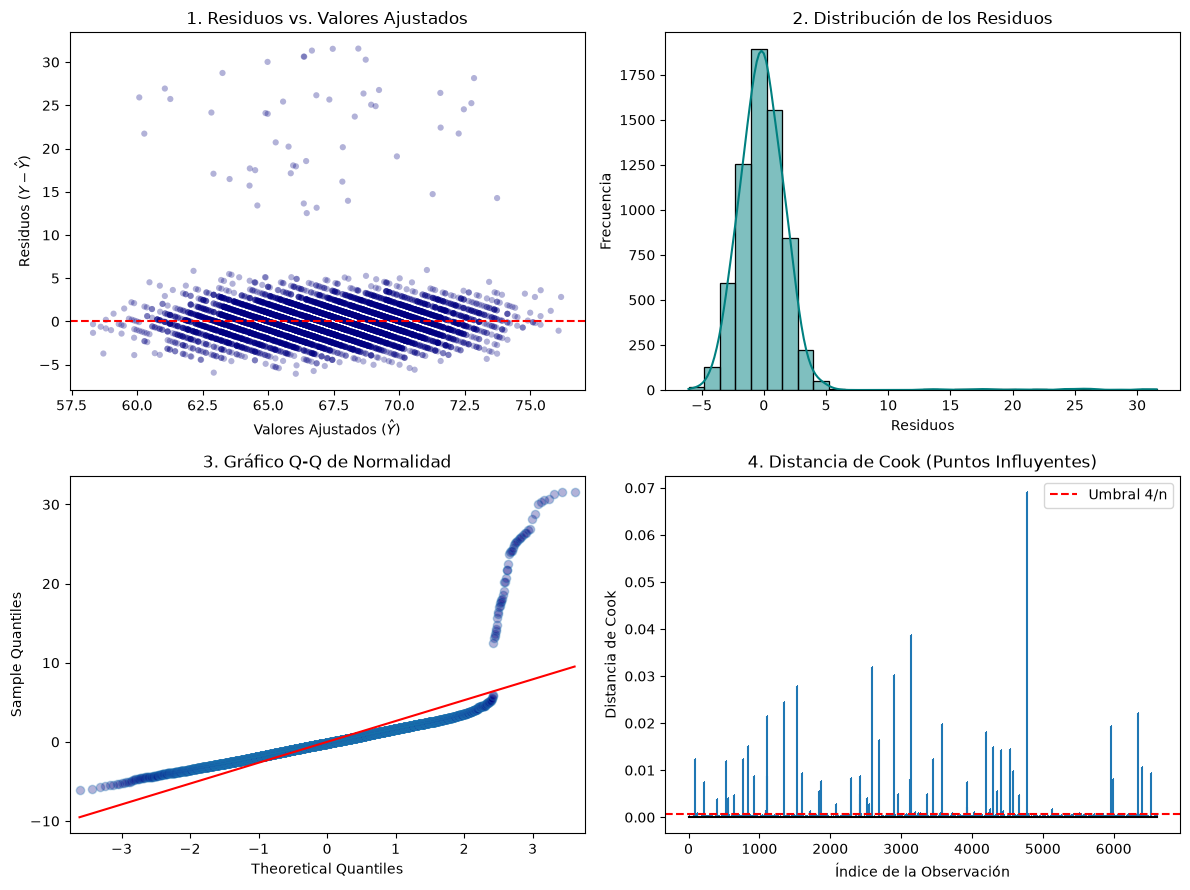

In [ ]:
# Code to create plots
m2 = smf.ols('Puntaje_en_el_examen ~ Horas_de_estudio + Porcentaje_de_asistencia', data=df).fit()

ajustados = m2.fittedvalues
residuos = m2.resid
influence = m2.get_influence()
cooks_d = influence.cooks_distance[0]
leverage = influence.hat_matrix_diag

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# 1. Residuos vs Ajustados
axes[0, 0].scatter(ajustados, residuos, alpha=0.3, color='navy', edgecolors='none', s=20)
axes[0, 0].axhline(y=0, color='red', linestyle='--')
axes[0, 0].set_xlabel('Valores Ajustados ($\hat{Y}$)')
axes[0, 0].set_ylabel('Residuos ($Y - \hat{Y}$)')
axes[0, 0].set_title('1. Residuos vs. Valores Ajustados')

# 2. Histograma de Residuos
sns.histplot(residuos, kde=True, ax=axes[0, 1], color='teal', bins=30)
axes[0, 1].set_xlabel('Residuos')
axes[0, 1].set_ylabel('Frecuencia')
axes[0, 1].set_title('2. Distribución de los Residuos')

# 3. Q-Q Plot
sm.qqplot(residuos, line='s', ax=axes[1, 0], markerfacecolor='navy', alpha=0.3)
axes[1, 0].set_title('3. Gráfico Q-Q de Normalidad')

# 4. Distancia de Cook
axes[1, 1].stem(range(len(cooks_d)), cooks_d, markerfmt=",", basefmt="k-")
axes[1, 1].axhline(y=4/len(df), color='red', linestyle='--', label='Umbral 4/n')
axes[1, 1].set_xlabel('Índice de la Observación')
axes[1, 1].set_ylabel('Distancia de Cook')
axes[1, 1].set_title('4. Distancia de Cook (Puntos Influyentes)')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('diagnostico_residuos.png')
print("Plots saved successfully.")

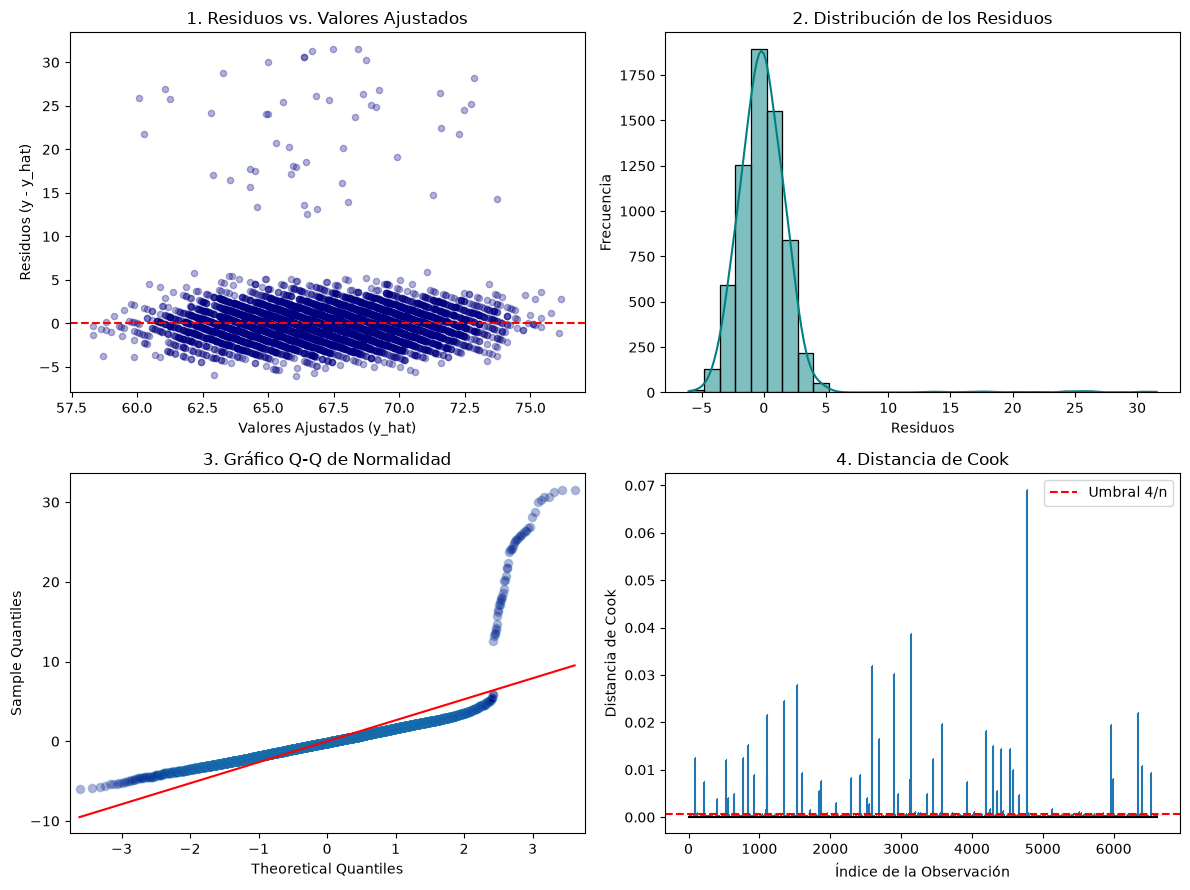

In [ ]:
# 1. Obtención de valores ajustados, residuos e indicadores de influencia (Modelo 2)
ajustados = m2.fittedvalues
residuos = m2.resid
influencia = m2.get_influence()
cooks_d = influencia.cooks_distance[0]

# 2. Configuración de la figura (2x2)
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Gráfico 1: Residuos vs. Valores Ajustados
axes[0, 0].scatter(ajustados, residuos, alpha=0.3, color='navy', s=20)
axes[0, 0].axhline(y=0, color='red', linestyle='--')
axes[0, 0].set_xlabel('Valores Ajustados (y_hat)')
axes[0, 0].set_ylabel('Residuos (y - y_hat)')
axes[0, 0].set_title('1. Residuos vs. Valores Ajustados')

# Gráfico 2: Histograma de Residuos
sns.histplot(residuos, kde=True, ax=axes[0, 1], color='teal', bins=30)
axes[0, 1].set_xlabel('Residuos')
axes[0, 1].set_ylabel('Frecuencia')
axes[0, 1].set_title('2. Distribución de los Residuos')

# Gráfico 3: Q-Q Plot de Normalidad
sm.qqplot(residuos, line='s', ax=axes[1, 0], markerfacecolor='navy', alpha=0.3)
axes[1, 0].set_title('3. Gráfico Q-Q de Normalidad')

# Gráfico 4: Distancia de Cook
axes[1, 1].stem(range(len(cooks_d)), cooks_d, markerfmt=",", basefmt="k-")
axes[1, 1].axhline(y=4/len(df), color='red', linestyle='--', label='Umbral 4/n')
axes[1, 1].set_xlabel('Índice de la Observación')
axes[1, 1].set_ylabel('Distancia de Cook')
axes[1, 1].set_title('4. Distancia de Cook')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

## Parte 8. Diagnóstico del modelo
### 8.1. ¿Se observa algún patrón en el gráfico de residuos vs. ajustados?

Comportamiento general: La gran mayoría de los datos se distribuye de manera horizontal y homogénea alrededor de la línea de cero ($y = 0$) en una banda estrecha entre $-5$ y $+5$ puntos, lo que confirma que la relación lineal y la homocedasticidad (varianza constante) se cumplen para el grueso de los estudiantes.

Presencia de valores atípicos superiores: Se observa un conjunto reducido de puntos dispersos en la zona positiva alta (residuos entre $+10$ y $+31$). Estos corresponden a estudiantes cuyo puntaje en el examen fue significativamente superior al estimado por sus horas de estudio y asistencia.

8.2. ¿La normalidad de residuos parece razonable?

Análisis del centro: La distribución es unimodal y está centrada exactamente en cero ($\text{Media} = 0.00$, $\text{Desviación Estándar} = 2.64$). En el gráfico Q-Q, los datos siguen fielmente la línea recta teórica de normalidad entre los cuantiles $-2.5$ y $+2.0$.

Comportamiento de las colas: Existe una asimetría positiva en la cola derecha derivada de las notas atípicas altas.

Conclusión: Sí, la normalidad es razonable para propósitos de inferencia. Gracias al Teorema del Límite Central y al gran tamaño de la muestra ($n = 6607$), las estimaciones de los errores estándar, así como las pruebas $t$ y $F$, son completamente válidas y robustas ante esta leve desviación en la cola superior.

### 8.3. ¿Existen observaciones con leverage alto o distancia de Cook elevada?

Leverage (Apalancamiento):\
El valor máximo de leverage en el conjunto de datos es $\text{h}_{\max} = 0.0027$.

En términos absolutos, es un valor sumamente bajo (muy lejano a 1.0), lo que demuestra que ninguna observación individual tiene combinaciones extremas en los predictores ($X$) capaces de deformar por sí solas la recta de regresión.

Distancia de Cook:\
La distancia de Cook máxima registrada es de 0.0691.

En la literatura estadística, un dato se considera severamente influyente si su distancia de Cook supera el umbral crítico de 0.5 o 1.0. Como el valor máximo ($0.0691$) está muy por debajo de estos límites, no existen observaciones con una capacidad desproporcionada de alteración sobre los coeficientes estimatedos ($\beta$).

### 8.4. Si encuentran observaciones influyentes, expliquen si necesariamente deben eliminarse
No, no deben eliminarse automáticamente.

Validez biológica y académica de los datos: Las observaciones con residuos elevados no representan errores de digitalización ni mediciones corruptas; corresponden a estudiantes reales con un rendimiento académico excepcionalmente alto por factores no contemplados en el modelo reducido.

Impacto real en los parámetros: Aunque estos datos tienen residuos grandes, su distancia de Cook es inferior a $0.1$, lo que prueba que no están sesgando ni distorsionando las pendientes del modelo. 

Riesgo de eliminación arbitraria: Eliminar datos válidos simplemente para forzar un gráfico más simétrico o elevar artificialmente el $R^2$ reduce la representatividad de la muestra y genera un sesgo de selección en el estudio. Se recomienda conservarlos y, en su defecto, reportar su presencia en el informe técnico. 

## Parte 9. Conclusión final
El análisis de regresión lineal múltiple determinó que el Porcentaje de asistencia y las Horas de estudio son las variables clave que mejor explican el desempeño del estudiante en el examen, alcanzando conjuntamente una capacidad explicativa del $54.11\%$ ($R^2 = 0.5413$). Al controlar por la asistencia, el coeficiente de las horas de estudio se ajustó de $0.289$ a $0.293$ puntos por hora y el intercepto disminuyó de $61.46$ a $45.60$, eliminando el sesgo por variable omitida del modelo simple. Aunque el tipo de colegio no mostró una diferencia directa de nivel ($p = 0.816$), sí existió evidencia de una interacción estadísticamente significativa con las horas de estudio ($p = 0.045$), indicando que el retorno por hora de estudio es ligeramente superior en el sector público ($0.300$ vs. $0.277$ puntos/hora). En conclusión, el modelo seleccionado resulta altamente útil tanto para explicar las dinámicas del rendimiento escolar como para predecir la calificación final, logrando un equilibrio óptimo entre parsimonia, significancia estadística global ($F = 3896$, $p < 0.001$) y bajo margen de error residual ($\approx 2.64$ puntos).

Resumen

Variables que mejor explican la respuesta: Porcentaje_de_asistencia ($\hat{\beta}_2 = 0.1973$) y Horas_de_estudio ($\hat{\beta}_1 = 0.2931$).

Cambio de efectos al controlar: Incluir la asistencia ajustó la pendiente de horas de estudio y redujo el intercepto base de $61.46$ a $45.60$ puntos. 

Evidencia de interacción: Sí, fue significativa ($p = 0.045$), mostrando una leve diferencia en la efectividad del tiempo de estudio entre colegios públicos y privados. 

Utilidad del modelo: Es muy útil para explicar el rendimiento ($R^2_{\text{ajustado}} = 54.11\%$, $F = 3896$, $p < 0.001$), manteniendo un error típico de estimación de solo $\approx 2.64$ puntos en la escala del examen. 